In [25]:
# nircam time

import dLux as dl
import jax.numpy as np
import jax
import matplotlib.pyplot as plt
import dLux.utils as dlu
from dLux.sources import Source
from jax import Array
from dLux.sources import BaseSource
from jax import vmap
import jax.random as jr
from dLux import spectra
from matplotlib.style import use
use('default')
jax.config.update("jax_enable_x64", True)
plt.rcParams['image.origin'] = 'lower'

from jax.scipy.special import gammaln, xlogy

def poisson_loglike_gamma(k, mu):
    # analytic continuation using gammaln(k+1)
    k = np.asarray(k, dtype=float)
    mu = np.asarray(mu, dtype=float)
    valid = (k >= 0) & np.isfinite(k) & (mu > 0) & np.isfinite(mu)
    logp = xlogy(k, mu) - mu - gammaln(k + 1.0)
    return np.where(valid, logp, -np.inf)

# define the likelihood function:
def poiss_loglike(pytree, data) -> float:
    """
    Poissonian log likelihood of the pytree given the data. Assumes the pytree
    has a .model() function.

    Parameters
    ----------
    pytree : Base
        Pytree with a .model() function.
    data : Array
        Data to compare the model to.

    Returns
    -------
    log_likelihood : Array
        Log likelihood of the pytree given the data.
    """
    return poisson_loglike_gamma(pytree.model(), data).sum()

def normal_logpdf(x, mu, sigma):
    z = (x-mu)/sigma
    return -0.5 * (np.log(2*np.pi) + 2*np.log(sigma) + z**2)


### OPTICA FIGURES: INTEXT FONTSIZE 10. CAPTIONS GENERALLY 8

# latex
import os
os.environ["PATH"] = "/Library/TeX/texbin:" + os.environ["PATH"]
import shutil
print(shutil.which("latex"))

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"""
\usepackage[T1]{fontenc}
\usepackage{newtxtext,newtxmath}
""",

    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 10,
})

plt.rcParams["figure.dpi"] = 300
# fig_width = 379.41753 / 72.27 # = 5.25
fig_width = 5.25

/Library/TeX/texbin/latex


In [220]:
eps = 1e-15
class CombinedSpectrum(dl.Spectrum):
    wavelengths: Array
    filt_weights: Array
    basis_weights: Array
    weights: Array
    flux: float

    def __init__(self, wavels, filt_weights, basis_weights):
        self.wavelengths = np.asarray(wavels, dtype=float)
        self.filt_weights = np.asarray(filt_weights, dtype=float)
        self.basis_weights = np.asarray(basis_weights, dtype=float)

        spec_w = self.spec_weights()
        detected_w = self.filt_weights * spec_w

        self.flux = detected_w.sum()
        self.weights = detected_w / self.flux
        
    def spec_weights(self):
        raise NotImplementedError

    def normalise(self):
        return self


class CombinedBasisSpectrum(CombinedSpectrum):
    basis_vects: Array

    def __init__(self, wavels, filt_weights, basis_weights, basis):
        self.basis_vects = np.asarray(basis, dtype=float)
        super().__init__(wavels, filt_weights, basis_weights)

    def spec_weights(self):
        return np.maximum(np.sum(self.basis_vects * self.basis_weights, axis=1), eps)
        # return 10 ** (np.sum(self.basis_vects * self.basis_weights, axis=1))

In [221]:
# spectrum interpolation
import dLux as dl
import jax
import jax.numpy as np
from jax import vmap


# -------------------------------------------------
# 0. A tiny monochromatic spectrum object
# -------------------------------------------------
# This reuses your existing CombinedBasisSpectrum machinery with 1 wavelength.
def monochromatic_spectrum(lam):
    return CombinedBasisSpectrum(
        wavels=np.array([lam]),
        filt_weights=np.array([1.0]),
        basis_weights=np.array([1.0]),
        basis=np.array([[1.0]]),
    )


# -------------------------------------------------
# 1. Pre-detector optical image at one wavelength
# -------------------------------------------------
def optics_image_lambda(lam, instrument):
    """
    Returns the optical image before the detector, while preserving the current
    source object (including source.position).

    Only the source spectrum is replaced by a monochromatic spectrum.
    """
    mono_spec = monochromatic_spectrum(lam)

    source = instrument.get("source")
    source = source.set("spectrum", mono_spec)
    source = source.set("flux", 1.0)  # unit source flux for basis image

    optics = instrument.optics
    # In dLux this is typically the source propagated through the optics.
    # If your local version uses a slightly different call, this is the only
    # line you should need to swap.
    return source.model(optics)


# -------------------------------------------------
# 2. Optical image and d/dlambda of optical image
# -------------------------------------------------
def optics_image_and_dlambda(lam, instrument):
    f = lambda x: optics_image_lambda(x, instrument)
    img = f(lam)
    dimg_dlam = jax.jacfwd(f)(lam)
    return img, dimg_dlam


# -------------------------------------------------
# 3. Evaluate those on the coarse wavelength grid
# -------------------------------------------------
def coarse_optics_images_and_derivs(wavelengths_coarse, instrument):
    imgs, dimgs = vmap(
        lambda lam: optics_image_and_dlambda(lam, instrument)
    )(wavelengths_coarse)

    # imgs.shape  = (Ncoarse, nx, ny)
    # dimgs.shape = (Ncoarse, nx, ny)
    return imgs, dimgs


# -------------------------------------------------
# 4. Dense fine-grid weights -> Hermite node coefficients
# -------------------------------------------------
def hermite_node_coeffs(wavelengths_fine, dense_weights, wavelengths_coarse):
    """
    For
        sum_j dense_weights[j] * O(lambda_fine[j]),
    compute coefficients multiplying coarse-node optical images and
    their wavelength derivatives under piecewise cubic Hermite interpolation.
    """
    wavelengths_fine = np.asarray(wavelengths_fine, dtype=float)
    dense_weights = np.asarray(dense_weights, dtype=float)
    wavelengths_coarse = np.asarray(wavelengths_coarse, dtype=float)

    n_coarse = wavelengths_coarse.size

    idx = np.searchsorted(wavelengths_coarse, wavelengths_fine, side="right") - 1
    idx = np.clip(idx, 0, n_coarse - 2)

    lam0 = wavelengths_coarse[idx]
    lam1 = wavelengths_coarse[idx + 1]
    dlam = lam1 - lam0

    t = (wavelengths_fine - lam0) / dlam

    h00 =  2*t**3 - 3*t**2 + 1
    h10 =      t**3 - 2*t**2 + t
    h01 = -2*t**3 + 3*t**2
    h11 =      t**3 -     t**2

    coeff_val = np.zeros(n_coarse, dtype=dense_weights.dtype)
    coeff_der = np.zeros(n_coarse, dtype=dense_weights.dtype)

    coeff_val = coeff_val.at[idx].add(dense_weights * h00)
    coeff_val = coeff_val.at[idx + 1].add(dense_weights * h01)

    coeff_der = coeff_der.at[idx].add(dense_weights * (dlam * h10))
    coeff_der = coeff_der.at[idx + 1].add(dense_weights * (dlam * h11))

    return coeff_val, coeff_der


# -------------------------------------------------
# 5. Apply detector once at the end
# -------------------------------------------------
def apply_detector(optical_image, instrument):
    detector = instrument.detector
    pixel_scale = instrument.optics.psf_pixel_scale
    oversample = instrument.optics.oversample
    pscale = pixel_scale/oversample
    psf = dl.PSF(optical_image, pscale)

    # If your detector object uses a slightly different method name,
    # this is the other line you may need to swap.
    return detector.model(psf)


# -------------------------------------------------
# 6. Hermite forward model: optics interpolation first, detector last
# -------------------------------------------------
def model_psf_hermite(spectrum, instrument, wavelengths_coarse):
    """
    spectrum:
        Same meaning as in your current model_psf. If source.spectrum is a
        CombinedBasisSpectrum, this can be the basis coefficients.

    instrument:
        Current Telescope(optics, source, detector). Source position etc. are kept.

    wavelengths_coarse:
        Coarse wavelength nodes where the optical image and d/dlambda are evaluated.
    """
    old_spec = instrument.get("source.spectrum")

    # reconstruct dense fine-grid spectrum from basis coefficients
    spec_w = np.maximum(old_spec.basis_vects @ spectrum, eps) # non log
    # spec_w = 10 ** (old_spec.basis_vects @ spectrum) # log

    # dense per-wavelength weights before normalisation
    dense_weights = old_spec.filt_weights * spec_w

    # same overall normalisation convention as your original model_psf
    flux_prefactor = spec_w.sum() / dense_weights.sum()

    # scalar coefficients multiplying coarse-node optical images/derivatives
    coeff_val, coeff_der = hermite_node_coeffs(
        wavelengths_fine=old_spec.wavelengths,
        dense_weights=dense_weights,
        wavelengths_coarse=wavelengths_coarse,
    )

    # evaluate pre-detector optical images and wavelength derivatives
    imgs, dimgs = coarse_optics_images_and_derivs(wavelengths_coarse, instrument)

    # reconstruct dense polychromatic optical image
    optical_image = (
        np.tensordot(coeff_val, imgs, axes=(0, 0)) +
        np.tensordot(coeff_der, dimgs, axes=(0, 0))
    )

    optical_image = flux_prefactor * optical_image

    # detector acts once, at the end
    return apply_detector(optical_image, instrument)


# normal model psf
def model_psf(spectrum, instrument):
    old_spec = instrument.get("source.spectrum")

    new_spec = CombinedBasisSpectrum(
        wavels=old_spec.wavelengths,
        filt_weights=old_spec.filt_weights,
        basis_weights=spectrum,
        basis=old_spec.basis_vects,
    )

    telescope = instrument.set("source.spectrum", new_spec)
    telescope = telescope.set("source.flux", telescope.get("source.spectrum").flux)
    
    return telescope.model()

In [222]:
import numpy as onp
def bin_filter_midpoints(wave, throughput, n_bins):
    """
    Bin a throughput curve into n_bins equal-width wavelength bins.

    Returns
    -------
    centres : array
        Midpoint wavelength of each bin.
    mean_throughput : array
        Average throughput in each bin.
    edges : array
        Bin edges.
    """
    wave = onp.asarray(wave)
    throughput = onp.asarray(throughput)

    order = onp.argsort(wave)
    wave = wave[order]
    throughput = throughput[order]

    edges = onp.linspace(wave.min(), wave.max(), n_bins + 1)
    centres = 0.5 * (edges[:-1] + edges[1:])

    mean_throughput = onp.zeros(n_bins)

    for i in range(n_bins):
        lo, hi = edges[i], edges[i + 1]

        mask = (wave >= lo) & (wave <= hi)

        # Include bin edges by interpolation so partial bins behave correctly
        w = onp.concatenate([[lo], wave[mask], [hi]])
        t = onp.interp(w, wave, throughput)

        # Remove duplicated points
        w, unique = onp.unique(w, return_index=True)
        t = t[unique]

        mean_throughput[i] = onp.trapezoid(t, w) / (hi - lo)

    return centres, mean_throughput, edges

In [223]:
## NIRCAM APERTURE CODE

import jax.numpy as np
from jax import Array
import dLux.utils as dlu

__all__ = [
    "axis_pixel_edges",
    "pixwt_exact",
    "filled_circle_exact",
    "reg_polygon_vertices",
]


def axis_pixel_edges(axis: Array) -> Array:
    """
    Calculates pixel-edge coordinates from a 1D array of pixel centres.

    Parameters
    ----------
    axis : Array
        Monotonic 1D array of pixel-centre coordinates.

    Returns
    -------
    edges : Array
        1D array of pixel-edge coordinates with length axis.size + 1.

    Notes
    -----
    This assumes a rectilinear grid whose pixels are bounded by the midpoints
    between neighbouring centres. The outer edges are linearly extrapolated.
    """
    axis = np.asarray(axis)

    if axis.ndim != 1:
        raise ValueError("axis must be 1D.")
    if axis.shape[0] < 2:
        raise ValueError("axis must contain at least two pixel centres.")

    mids = 0.5 * (axis[1:] + axis[:-1])
    first = axis[0] - 0.5 * (axis[1] - axis[0])
    last = axis[-1] + 0.5 * (axis[-1] - axis[-2])

    return np.concatenate([first[None], mids, last[None]])


def _atan_ratio(y: Array, x: Array) -> Array:
    """
    Robust version of arctan(y/x) with sensible behaviour for x = 0.
    """
    x = np.asarray(x)
    y = np.asarray(y)

    x_safe = np.where(x == 0, 1.0, x)
    out = np.arctan(y / x_safe)
    out = np.where(x == 0, 0.5 * np.pi * np.sign(y), out)
    out = np.where((x == 0) & (y == 0), 0.0, out)
    return out


def _arc_exact(x: Array, y0: Array, y1: Array, r: float) -> Array:
    """
    Computes the signed area of the circular sector between the rays from the
    origin through (x, y0) and (x, y1).
    """
    return 0.5 * r**2 * (_atan_ratio(y1, x) - _atan_ratio(y0, x))


def _chord_exact(x: Array, y0: Array, y1: Array) -> Array:
    """
    Computes the signed area of the triangle with vertices
    (0, 0), (x, y0), and (x, y1).
    """
    return 0.5 * x * (y1 - y0)


def _oneside_exact(x: Array, y0: Array, y1: Array, r: float) -> Array:
    """
    Computes the signed area of intersection between the circle x^2 + y^2 <= r^2
    and the triangle with vertices (0, 0), (x, y0), and (x, y1).

    This is a JAX translation of the POPPY/pixwt logic.
    """
    x = np.asarray(x)
    y0 = np.asarray(y0)
    y1 = np.asarray(y1)

    x, y0, y1 = np.broadcast_arrays(x, y0, y1)

    zero = np.zeros_like(x, dtype=float)

    absx = np.abs(x)
    inside_strip = absx < r
    outside_strip = ~inside_strip

    yh = np.sqrt(np.clip(r**2 - x**2, 0.0, None))

    ans = np.where(outside_strip, _arc_exact(x, y0, y1, r), zero)

    # Case 1: y0 <= -yh
    c1 = (y0 <= -yh) & inside_strip

    m = (y1 <= -yh) & c1
    ans = ans + np.where(m, _arc_exact(x, y0, y1, r), zero)

    m = (y1 > -yh) & (y1 <= yh) & c1
    ans = ans + np.where(
        m,
        _arc_exact(x, y0, -yh, r) + _chord_exact(x, -yh, y1),
        zero,
    )

    m = (y1 > yh) & c1
    ans = ans + np.where(
        m,
        _arc_exact(x, y0, -yh, r)
        + _chord_exact(x, -yh, yh)
        + _arc_exact(x, yh, y1, r),
        zero,
    )

    # Case 2: -yh < y0 < yh
    c2 = (y0 > -yh) & (y0 < yh) & inside_strip

    m = (y1 <= -yh) & c2
    ans = ans + np.where(
        m,
        _chord_exact(x, y0, -yh) + _arc_exact(x, -yh, y1, r),
        zero,
    )

    m = (y1 > -yh) & (y1 <= yh) & c2
    ans = ans + np.where(m, _chord_exact(x, y0, y1), zero)

    m = (y1 > yh) & c2
    ans = ans + np.where(
        m,
        _chord_exact(x, y0, yh) + _arc_exact(x, yh, y1, r),
        zero,
    )

    # Case 3: y0 >= yh
    c3 = (y0 >= yh) & inside_strip

    m = (y1 <= -yh) & c3
    ans = ans + np.where(
        m,
        _arc_exact(x, y0, yh, r)
        + _chord_exact(x, yh, -yh)
        + _arc_exact(x, -yh, y1, r),
        zero,
    )

    m = (y1 > -yh) & (y1 <= yh) & c3
    ans = ans + np.where(
        m,
        _arc_exact(x, y0, yh, r) + _chord_exact(x, yh, y1),
        zero,
    )

    m = (y1 > yh) & c3
    ans = ans + np.where(m, _arc_exact(x, y0, y1, r), zero)

    # Degenerate zero-width triangles have zero area.
    return np.where(x == 0, 0.0, ans)


def _intarea_exact(
    xc: float,
    yc: float,
    r: float,
    x0: Array,
    x1: Array,
    y0: Array,
    y1: Array,
) -> Array:
    """
    Computes the exact area of overlap between a circle and an axis-aligned rectangle.

    Parameters
    ----------
    xc, yc : float
        Circle centre.
    r : float
        Circle radius.
    x0, x1, y0, y1 : Array
        Rectangle bounds. These may be scalars or broadcastable arrays.

    Returns
    -------
    area : Array
        Overlap area between the circle and rectangle.
    """
    x0 = np.asarray(x0) - xc
    x1 = np.asarray(x1) - xc
    y0 = np.asarray(y0) - yc
    y1 = np.asarray(y1) - yc

    return (
        _oneside_exact(x1, y0, y1, r)
        + _oneside_exact(y1, -x1, -x0, r)
        + _oneside_exact(-x0, -y1, -y0, r)
        + _oneside_exact(-y0, x0, x1, r)
    )


def pixwt_exact(
    xc: float,
    yc: float,
    r: float,
    x: Array,
    y: Array,
    dx: Array | float = 1.0,
    dy: Array | float | None = None,
) -> Array:
    """
    Computes the fractional area of a pixel interior to a circle.

    Parameters
    ----------
    xc, yc : float
        Circle centre.
    r : float
        Circle radius.
    x, y : Array
        Pixel-centre coordinates.
    dx, dy : Array | float
        Pixel widths in x and y. If dy is None, dy = dx.

    Returns
    -------
    frac : Array
        Fraction of each pixel covered by the circle.
    """
    if dy is None:
        dy = dx

    x = np.asarray(x)
    y = np.asarray(y)
    dx = np.asarray(dx)
    dy = np.asarray(dy)

    x0 = x - 0.5 * dx
    x1 = x + 0.5 * dx
    y0 = y - 0.5 * dy
    y1 = y + 0.5 * dy

    area = _intarea_exact(xc, yc, r, x0, x1, y0, y1)
    pix_area = dx * dy

    return np.clip(dlu.math.nandiv(area, pix_area, fill=0.0), 0.0, 1.0)


def filled_circle_exact(
    coords: Array,
    radius: float,
    centre: Array | None = None,
    invert: bool = False,
    fill_value: float = 1.0,
) -> Array:
    """
    Calculates an exactly area-weighted filled circle on a rectilinear grid.

    Parameters
    ----------
    coords : Array
        Coordinate array with shape (2, ny, nx), in standard dLux format.
        coords[0] is x and coords[1] is y.
    radius : float
        Circle radius.
    centre : Array | None
        Circle centre as [x, y]. If None, uses [0, 0].
    invert : bool = False
        Whether to invert the mask.
    fill_value : float = 1.0
        Value of a fully covered pixel.

    Returns
    -------
    circle : Array
        Fractional circle mask with exact subpixel edge weights.

    Notes
    -----
    This assumes the grid is rectilinear and axis-aligned, i.e. x varies only
    along columns and y varies only along rows.
    """
    if centre is None:
        centre = np.zeros(2)

    xc, yc = centre

    x_centres = coords[0, 0, :]
    y_centres = coords[1, :, 0]

    x_edges = axis_pixel_edges(x_centres)
    y_edges = axis_pixel_edges(y_centres)

    dx = x_edges[1:] - x_edges[:-1]
    dy = y_edges[1:] - y_edges[:-1]

    x = x_centres[None, :]
    y = y_centres[:, None]
    dx = dx[None, :]
    dy = dy[:, None]

    frac = pixwt_exact(xc, yc, radius, x, y, dx=dx, dy=dy)

    if invert:
        frac = 1.0 - frac

    return fill_value * frac


def reg_polygon_vertices(
    nsides: int,
    radius: float,
    centre: Array | None = None,
    angle: float = 0.0,
) -> Array:
    """
    Generates floating-point vertex positions for a regular polygon.

    Parameters
    ----------
    nsides : int
        Number of polygon sides.
    radius : float
        Circumradius of the polygon.
    centre : Array | None
        Polygon centre as [x, y]. If None, uses [0, 0].
    angle : float = 0.0
        Rotation angle in radians.

    Returns
    -------
    vertices : Array
        Array of shape (nsides, 2) containing [x, y] vertex positions.
    """
    if centre is None:
        centre = np.zeros(2)

    theta = angle + np.linspace(0.0, 2.0 * np.pi, nsides, endpoint=False)
    verts = radius * np.stack([np.cos(theta), np.sin(theta)], axis=-1)
    return verts + centre[None, :]

import jax.numpy as np
from jax import lax, vmap, Array

__all__ = [
    "pixel_corner_grid",
    "pixel_quads",
    "filled_polygon_exact",
]


def _cross2(a: Array, b: Array) -> Array:
    """
    Calculates the 2D cross product a_x b_y - a_y b_x.
    """
    return a[..., 0] * b[..., 1] - a[..., 1] * b[..., 0]


def _safe_divide(num: Array, den: Array, fill: float = 0.0) -> Array:
    """
    Safely divides num by den, returning fill where den is zero.
    """
    good = np.abs(den) > 1e-15
    return np.where(good, num / den, fill)


def _polygon_signed_area(vertices: Array) -> Array:
    """
    Calculates the signed area of a polygon.

    Parameters
    ----------
    vertices : Array
        Polygon vertices with shape (n, 2).

    Returns
    -------
    area : Array
        Signed polygon area.
    """
    x = vertices[:, 0]
    y = vertices[:, 1]
    xr = np.roll(x, -1)
    yr = np.roll(y, -1)
    return 0.5 * np.sum(x * yr - y * xr)


def _polygon_signed_area_n(vertices: Array, n: int) -> Array:
    """
    Calculates the signed area of the first n vertices of a padded polygon array.

    Parameters
    ----------
    vertices : Array
        Padded polygon vertices with shape (nmax, 2).
    n : int
        Number of active vertices.

    Returns
    -------
    area : Array
        Signed polygon area of the active polygon.
    """
    nmax = vertices.shape[0]
    n_safe = np.maximum(n, 1)

    def body(i, area):
        valid = i < n
        j = (i + 1) % n_safe

        xi = vertices[i, 0]
        yi = vertices[i, 1]
        xj = vertices[j, 0]
        yj = vertices[j, 1]

        contrib = 0.5 * (xi * yj - yi * xj)
        return area + np.where(valid, contrib, 0.0)

    return lax.fori_loop(0, nmax, body, 0.0)


def _ensure_ccw(vertices: Array) -> Array:
    """
    Reverses polygon vertex order if necessary so that the polygon is CCW.
    """
    return np.where(
        _polygon_signed_area(vertices) < 0,
        vertices[::-1],
        vertices,
    )


def _append_vertex(vertices: Array, count: int, point: Array) -> tuple[Array, int]:
    """
    Appends a vertex to a padded polygon array.
    """
    vertices = vertices.at[count].set(point)
    return vertices, count + 1


def _segment_line_intersection(
    s: Array,
    e: Array,
    a: Array,
    b: Array,
) -> Array:
    """
    Computes the intersection between the segment line s->e and the infinite line a->b.
    """
    r = e - s
    t = b - a
    den = _cross2(r, t)
    u = _safe_divide(_cross2(a - s, t), den, fill=0.0)
    return s + u * r


def _inside_half_plane(p: Array, a: Array, b: Array) -> Array:
    """
    Tests whether p lies inside the CCW half-plane defined by edge a->b.
    """
    return _cross2(b - a, p - a) >= 0.0


def _clip_against_edge(
    vertices: Array,
    nverts: int,
    a: Array,
    b: Array,
) -> tuple[Array, int]:
    """
    Clips a padded polygon against a single CCW clip edge a->b.
    """
    nmax = vertices.shape[0]
    n_safe = np.maximum(nverts, 1)
    out = np.zeros_like(vertices)

    def body(i, state):
        out_vertices, out_count = state

        valid = i < nverts
        prev_i = (i - 1) % n_safe

        s = vertices[prev_i]
        e = vertices[i]

        s_in = _inside_half_plane(s, a, b)
        e_in = _inside_half_plane(e, a, b)

        inter = _segment_line_intersection(s, e, a, b)

        # outside -> inside : append intersection, endpoint
        cond = valid & (~s_in) & e_in
        out_vertices, out_count = lax.cond(
            cond,
            lambda st: _append_vertex(*_append_vertex(st[0], st[1], inter), e),
            lambda st: st,
            (out_vertices, out_count),
        )

        # inside -> outside : append intersection
        cond = valid & s_in & (~e_in)
        out_vertices, out_count = lax.cond(
            cond,
            lambda st: _append_vertex(st[0], st[1], inter),
            lambda st: st,
            (out_vertices, out_count),
        )

        # inside -> inside : append endpoint
        cond = valid & s_in & e_in
        out_vertices, out_count = lax.cond(
            cond,
            lambda st: _append_vertex(st[0], st[1], e),
            lambda st: st,
            (out_vertices, out_count),
        )

        return out_vertices, out_count

    return lax.fori_loop(0, nmax, body, (out, 0))


def _clip_polygon_to_quad(vertices: Array, quad: Array) -> tuple[Array, int]:
    """
    Clips a polygon against a convex quadrilateral.

    Parameters
    ----------
    vertices : Array
        Polygon vertices with shape (n, 2).
    quad : Array
        Convex quad vertices with shape (4, 2).

    Returns
    -------
    clipped : Array
        Padded clipped polygon vertices with shape (n + 4, 2).
    nclip : int
        Number of active clipped vertices.
    """
    nverts = vertices.shape[0]
    padded = np.zeros((nverts + 4, 2), dtype=vertices.dtype)
    padded = padded.at[:nverts].set(vertices)

    quad = _ensure_ccw(quad)

    def body(k, state):
        poly, n = state
        a = quad[k]
        b = quad[(k + 1) % 4]
        return _clip_against_edge(poly, n, a, b)

    return lax.fori_loop(0, 4, body, (padded, nverts))


def _quad_area(quad: Array) -> Array:
    """
    Calculates the absolute area of a quadrilateral.
    """
    return np.abs(_polygon_signed_area(quad))


def _polygon_bbox(vertices: Array) -> tuple[Array, Array]:
    """
    Calculates the bounding box of a polygon.
    """
    return vertices.min(axis=0), vertices.max(axis=0)


def _quad_bbox(quad: Array) -> tuple[Array, Array]:
    """
    Calculates the bounding box of a quadrilateral.
    """
    return quad.min(axis=0), quad.max(axis=0)


def _bbox_overlap(min0: Array, max0: Array, min1: Array, max1: Array) -> Array:
    """
    Tests whether two axis-aligned bounding boxes overlap.
    """
    return (
        (max0[0] >= min1[0])
        & (min0[0] <= max1[0])
        & (max0[1] >= min1[1])
        & (min0[1] <= max1[1])
    )


def _polygon_quad_fraction(vertices: Array, quad: Array) -> Array:
    """
    Calculates the fractional coverage of a quad by a polygon.
    """
    poly_min, poly_max = _polygon_bbox(vertices)
    quad_min, quad_max = _quad_bbox(quad)

    overlap = _bbox_overlap(poly_min, poly_max, quad_min, quad_max)

    def calc_fn(q):
        clipped, nclip = _clip_polygon_to_quad(vertices, q)
        area = np.abs(_polygon_signed_area_n(clipped, nclip))
        return np.clip(_safe_divide(area, _quad_area(q), fill=0.0), 0.0, 1.0)

    return lax.cond(overlap, calc_fn, lambda q: 0.0, quad)


def pixel_corner_grid(coords: Array) -> Array:
    """
    Reconstructs a corner grid from a dLux-style centre-coordinate grid.

    Parameters
    ----------
    coords : Array
        Coordinate array with shape (2, ny, nx).

    Returns
    -------
    corners : Array
        Corner coordinates with shape (ny + 1, nx + 1, 2).

    Notes
    -----
    The interior corners are the average of the four surrounding pixel centres.
    Boundary corners are linearly extrapolated. For arbitrary distorted coords,
    this defines a piecewise-linear pixel mesh.
    """
    if coords.ndim != 3 or coords.shape[0] != 2:
        raise ValueError("coords must have shape (2, ny, nx).")

    centres = np.moveaxis(coords, 0, -1)  # (ny, nx, 2)
    ny, nx, _ = centres.shape

    if ny < 2 or nx < 2:
        raise ValueError("coords must have at least shape (2, 2, 2).")

    pad = np.zeros((ny + 2, nx + 2, 2), dtype=centres.dtype)
    pad = pad.at[1:-1, 1:-1].set(centres)

    # Extrapolate top and bottom rows
    pad = pad.at[0, 1:-1].set(2.0 * centres[0] - centres[1])
    pad = pad.at[-1, 1:-1].set(2.0 * centres[-1] - centres[-2])

    # Extrapolate left and right columns
    pad = pad.at[:, 0].set(2.0 * pad[:, 1] - pad[:, 2])
    pad = pad.at[:, -1].set(2.0 * pad[:, -2] - pad[:, -3])

    corners = 0.25 * (
        pad[:-1, :-1]
        + pad[1:, :-1]
        + pad[:-1, 1:]
        + pad[1:, 1:]
    )

    return corners


def pixel_quads(coords: Array) -> Array:
    """
    Builds per-pixel quadrilaterals from a dLux-style coordinate grid.

    Parameters
    ----------
    coords : Array
        Coordinate array with shape (2, ny, nx).

    Returns
    -------
    quads : Array
        Pixel quads with shape (ny, nx, 4, 2), ordered CCW.
    """
    corners = pixel_corner_grid(coords)

    v00 = corners[:-1, :-1]
    v10 = corners[:-1, 1:]
    v11 = corners[1:, 1:]
    v01 = corners[1:, :-1]

    quads = np.stack([v00, v10, v11, v01], axis=2)

    signed = 0.5 * np.sum(
        quads[..., :, 0] * np.roll(quads[..., :, 1], -1, axis=-1)
        - quads[..., :, 1] * np.roll(quads[..., :, 0], -1, axis=-1),
        axis=-1,
    )

    return np.where(signed[..., None, None] < 0, quads[..., ::-1, :], quads)


def filled_polygon_exact(
    coords: Array,
    vertices: Array,
    invert: bool = False,
    fill_value: float = 1.0,
) -> Array:
    """
    Calculates an exactly area-weighted filled polygon on a coordinate grid.

    Parameters
    ----------
    coords : Array
        Coordinate array with shape (2, ny, nx).
    vertices : Array
        Polygon vertices with shape (n, 2), given in the same coordinate system
        as `coords`. Vertices should trace the polygon boundary in order and should
        not repeat the first vertex at the end.
    invert : bool = False
        Whether to invert the mask.
    fill_value : float = 1.0
        Value of a fully covered pixel.

    Returns
    -------
    polygon : Array
        Fractional polygon mask with exact subpixel edge weights.

    Notes
    -----
    - This is exact for the polygon/quad intersections of the reconstructed pixel mesh.
    - Works for floating-point vertex positions, so vertices may be placed at fully
      subpixel positions.
    - The polygon should be simple (non-self-intersecting).
    """
    if vertices.ndim != 2 or vertices.shape[1] != 2:
        raise ValueError("vertices must have shape (n, 2).")
    if vertices.shape[0] < 3:
        raise ValueError("vertices must contain at least three points.")

    quads = pixel_quads(coords)
    ny, nx = quads.shape[:2]

    flat_quads = quads.reshape((-1, 4, 2))
    frac = vmap(lambda q: _polygon_quad_fraction(vertices, q))(flat_quads)
    frac = frac.reshape((ny, nx))

    if invert:
        frac = 1.0 - frac

    return fill_value * frac

import jax.numpy as np
from jax import Array
import dLux.utils as dlu

__all__ = [
    "translate_vertices",
    "rotate_vertices",
]


def translate_vertices(vertices: Array, translation: Array) -> Array:
    """
    Translates polygon vertices by a constant offset.

    Parameters
    ----------
    vertices : Array
        Vertex array with shape (..., 2).
    translation : Array
        Translation vector [dx, dy].

    Returns
    -------
    vertices : Array
        Translated vertices.
    """
    vertices = np.asarray(vertices)
    translation = np.asarray(translation)

    if vertices.shape[-1] != 2:
        raise ValueError("vertices must have shape (..., 2).")
    if translation.shape != (2,):
        raise ValueError("translation must have shape (2,).")

    return vertices + translation


def rotate_vertices(
    vertices: Array,
    angle: float,
    centre: Array | None = None,
    degrees: bool = False,
) -> Array:
    """
    Rotates polygon vertices about a specified centre.

    Parameters
    ----------
    vertices : Array
        Vertex array with shape (..., 2).
    angle : float
        Rotation angle. Interpreted as radians unless `degrees=True`.
    centre : Array | None = None
        Centre of rotation [x, y]. Defaults to [0, 0].
    degrees : bool = False
        Whether the angle is specified in degrees.

    Returns
    -------
    vertices : Array
        Rotated vertices.
    """
    vertices = np.asarray(vertices)

    if vertices.shape[-1] != 2:
        raise ValueError("vertices must have shape (..., 2).")

    if centre is None:
        centre = np.zeros(2, dtype=vertices.dtype)
    else:
        centre = np.asarray(centre)

    if centre.shape != (2,):
        raise ValueError("centre must have shape (2,).")

    if degrees:
        angle = dlu.deg2rad(angle)

    c = np.cos(angle)
    s = np.sin(angle)

    rot = np.array([
        [c, -s],
        [s,  c],
    ])

    shifted = vertices - centre
    rotated = shifted @ rot.T
    return rotated + centre

import jax.numpy as np
import equinox as eqx
from jax import Array

from stpsf.constants import JWST_PRIMARY_SEGMENTS, JWST_PRIMARY_STRUTS


__all__ = [
    "webb_primary_segments",
    "webb_primary_struts",
    "webb_primary_aperture",
    "WebbPrimaryAperture",
]


def _canonicalise_vertices(vertices: Array) -> Array:
    """
    Removes a repeated closing vertex if present.

    Parameters
    ----------
    vertices : Array
        Vertex array with shape (n, 2).

    Returns
    -------
    vertices : Array
        Canonicalised vertex array.
    """
    vertices = np.asarray(vertices)
    if vertices.ndim != 2 or vertices.shape[1] != 2:
        raise ValueError("vertices must have shape (n, 2).")

    # Some of the strut polygons repeat the first vertex at the end.
    if vertices.shape[0] >= 2 and np.allclose(vertices[0], vertices[-1]):
        return vertices[:-1]
    return vertices


def _segment_id_from_name(name: str) -> int:
    """
    Extracts the WSS-like integer segment id from names such as 'A1-1'.
    """
    return int(name.split("-")[1])


def _stack_polygon_masks(coords: Array, polydata: tuple) -> Array:
    """
    Rasterises a collection of polygons into a stacked mask array.

    Parameters
    ----------
    coords : Array
        Coordinate array with shape (2, ny, nx).
    polydata : tuple
        Tuple of (name, vertices) polygon definitions.

    Returns
    -------
    masks : Array
        Array of shape (npoly, ny, nx).
    """
    masks = [
        filled_polygon_exact(coords, _canonicalise_vertices(vertices))
        for _, vertices in polydata
    ]
    return np.stack(masks, axis=0)


def webb_primary_segments(
    coords: Array,
    label_segments: bool = False,
    return_individual: bool = False,
) -> Array | tuple[Array, Array]:
    """
    Rasterises the JWST primary mirror segments from their tabulated vertices.

    Parameters
    ----------
    coords : Array
        Coordinate array with shape (2, ny, nx).
    label_segments : bool = False
        If True, returns a segment label map instead of a transmission mask.
        The label in each pixel is taken from the segment with the largest
        fractional coverage in that pixel.
    return_individual : bool = False
        If True, also returns the individual per-segment masks with shape
        (18, ny, nx).

    Returns
    -------
    segments : Array
        If `label_segments=False`, returns the summed segment transmission mask.
        If `label_segments=True`, returns the segment label map.
    masks : Array, optional
        Individual per-segment masks, returned only if `return_individual=True`.

    Notes
    -----
    Since the segment polygons are disjoint apart from shared boundaries/gaps,
    summing their exact rasterisations is the natural combination.
    """
    seg_masks = _stack_polygon_masks(coords, JWST_PRIMARY_SEGMENTS)

    if label_segments:
        seg_ids = np.array(
            [_segment_id_from_name(name) for name, _ in JWST_PRIMARY_SEGMENTS],
            dtype=int,
        )
        best = np.argmax(seg_masks, axis=0)
        best_frac = np.max(seg_masks, axis=0)
        labels = np.where(best_frac > 0, seg_ids[best], 0)
        out = labels
    else:
        out = np.clip(np.sum(seg_masks, axis=0), 0.0, 1.0)

    if return_individual:
        return out, seg_masks
    return out


def webb_primary_struts(
    coords: Array,
    return_individual: bool = False,
    combine_mode: str = "clip_sum",
) -> Array | tuple[Array, Array]:
    """
    Rasterises the JWST secondary support struts from their tabulated vertices.

    Parameters
    ----------
    coords : Array
        Coordinate array with shape (2, ny, nx).
    return_individual : bool = False
        If True, also returns the individual per-strut masks.
    combine_mode : str = "clip_sum"
        How to combine individual strut masks. Supported values are:
        - "clip_sum" : sum and clip to [0, 1]
        - "max"      : take pixelwise maximum

    Returns
    -------
    struts : Array
        Combined strut obscuration mask.
    masks : Array, optional
        Individual per-strut masks, returned only if `return_individual=True`.

    Notes
    -----
    The strut polygons include overlapping pieces (for instance `strut3` and
    `strut3_bumps`). A full exact union would require polygon boolean union.
    The options here are practical array-space approximations after exact
    per-polygon rasterisation.
    """
    strut_masks = _stack_polygon_masks(coords, JWST_PRIMARY_STRUTS)

    if combine_mode == "clip_sum":
        out = np.clip(np.sum(strut_masks, axis=0), 0.0, 1.0)
    elif combine_mode == "max":
        out = np.max(strut_masks, axis=0)
    else:
        raise ValueError("combine_mode must be 'clip_sum' or 'max'.")

    if return_individual:
        return out, strut_masks
    return out


def webb_primary_aperture(
    coords: Array,
    label_segments: bool = False,
    strut_combine_mode: str = "clip_sum",
    aperture_combine_mode: str = "subtract",
    return_components: bool = False,
) -> Array | tuple[Array, Array, Array]:
    """
    Generates the JWST primary aperture from exact polygon rasterisations of
    the segment and strut vertex data.

    Parameters
    ----------
    coords : Array
        Coordinate array with shape (2, ny, nx).
    label_segments : bool = False
        If True, returns a segment label map masked by the struts.
    strut_combine_mode : str = "clip_sum"
        Method used to combine the individual strut masks. Passed to
        `webb_primary_struts`.
    aperture_combine_mode : str = "subtract"
        Method used to combine segment and strut masks. Supported values are:
        - "subtract" : clip(segment_mask - strut_mask, 0, 1)
        - "multiply" : segment_mask * (1 - strut_mask)
    return_components : bool = False
        If True, also returns the segment mask and strut mask separately.

    Returns
    -------
    aperture : Array
        JWST aperture transmission mask or segment label map.
    segment_mask : Array, optional
        Rasterised segment mask, returned only if `return_components=True`.
    strut_mask : Array, optional
        Rasterised strut mask, returned only if `return_components=True`.

    Notes
    -----
    - Segment polygons are rasterised exactly against pixels.
    - Strut polygons are rasterised exactly against pixels.
    - The final composition is performed in array space, so this is not a
      mathematically exact polygon-boolean difference everywhere. It is,
      however, substantially better than centre-sampled point-in-polygon logic.

    The default `aperture_combine_mode="subtract"` is usually the more sensible
    choice for thin obscurations cutting through already-filled regions, since
    if a pixel lies fully inside a segment then
        transmission = 1 - strut_fraction
    is recovered exactly.
    """
    seg_mask = webb_primary_segments(coords, label_segments=False)
    strut_mask = webb_primary_struts(coords, combine_mode=strut_combine_mode)

    if aperture_combine_mode == "subtract":
        aper = np.clip(seg_mask - strut_mask, 0.0, 1.0)
    elif aperture_combine_mode == "multiply":
        aper = seg_mask * (1.0 - strut_mask)
    else:
        raise ValueError("aperture_combine_mode must be 'subtract' or 'multiply'.")

    if label_segments:
        labels = webb_primary_segments(coords, label_segments=True)
        labels = np.where(aper > 0, labels, 0)
        out = labels
    else:
        out = aper

    if return_components:
        return out, seg_mask, strut_mask
    return out


class WebbPrimaryAperture(eqx.Module):
    """
    dLux-style JWST primary aperture generator based on exact polygon rasterisation.

    Parameters
    ----------
    label_segments : bool = False
        Whether to return a segment label map instead of a transmission mask.
    strut_combine_mode : str = "clip_sum"
        Method used to combine the strut polygons.
    aperture_combine_mode : str = "subtract"
        Method used to combine the segment mask and strut mask.
    """
    label_segments: bool = eqx.field(static=True, default=False)
    strut_combine_mode: str = eqx.field(static=True, default="clip_sum")
    aperture_combine_mode: str = eqx.field(static=True, default="subtract")

    def __call__(self, coords: Array) -> Array:
        """
        Evaluates the JWST primary aperture on the supplied coordinates.

        Parameters
        ----------
        coords : Array
            Coordinate array with shape (2, ny, nx).

        Returns
        -------
        aperture : Array
            JWST aperture transmission mask or segment label map.
        """
        return webb_primary_aperture(
            coords,
            label_segments=self.label_segments,
            strut_combine_mode=self.strut_combine_mode,
            aperture_combine_mode=self.aperture_combine_mode,
        )

In [224]:
wf_npix = 1024
diameter = 6.603464
coords = dlu.pixel_coords(wf_npix, diameter)
aperture = webb_primary_aperture(coords)

In [231]:
# short first, then long
eigvals_all = []
a0s_all = []

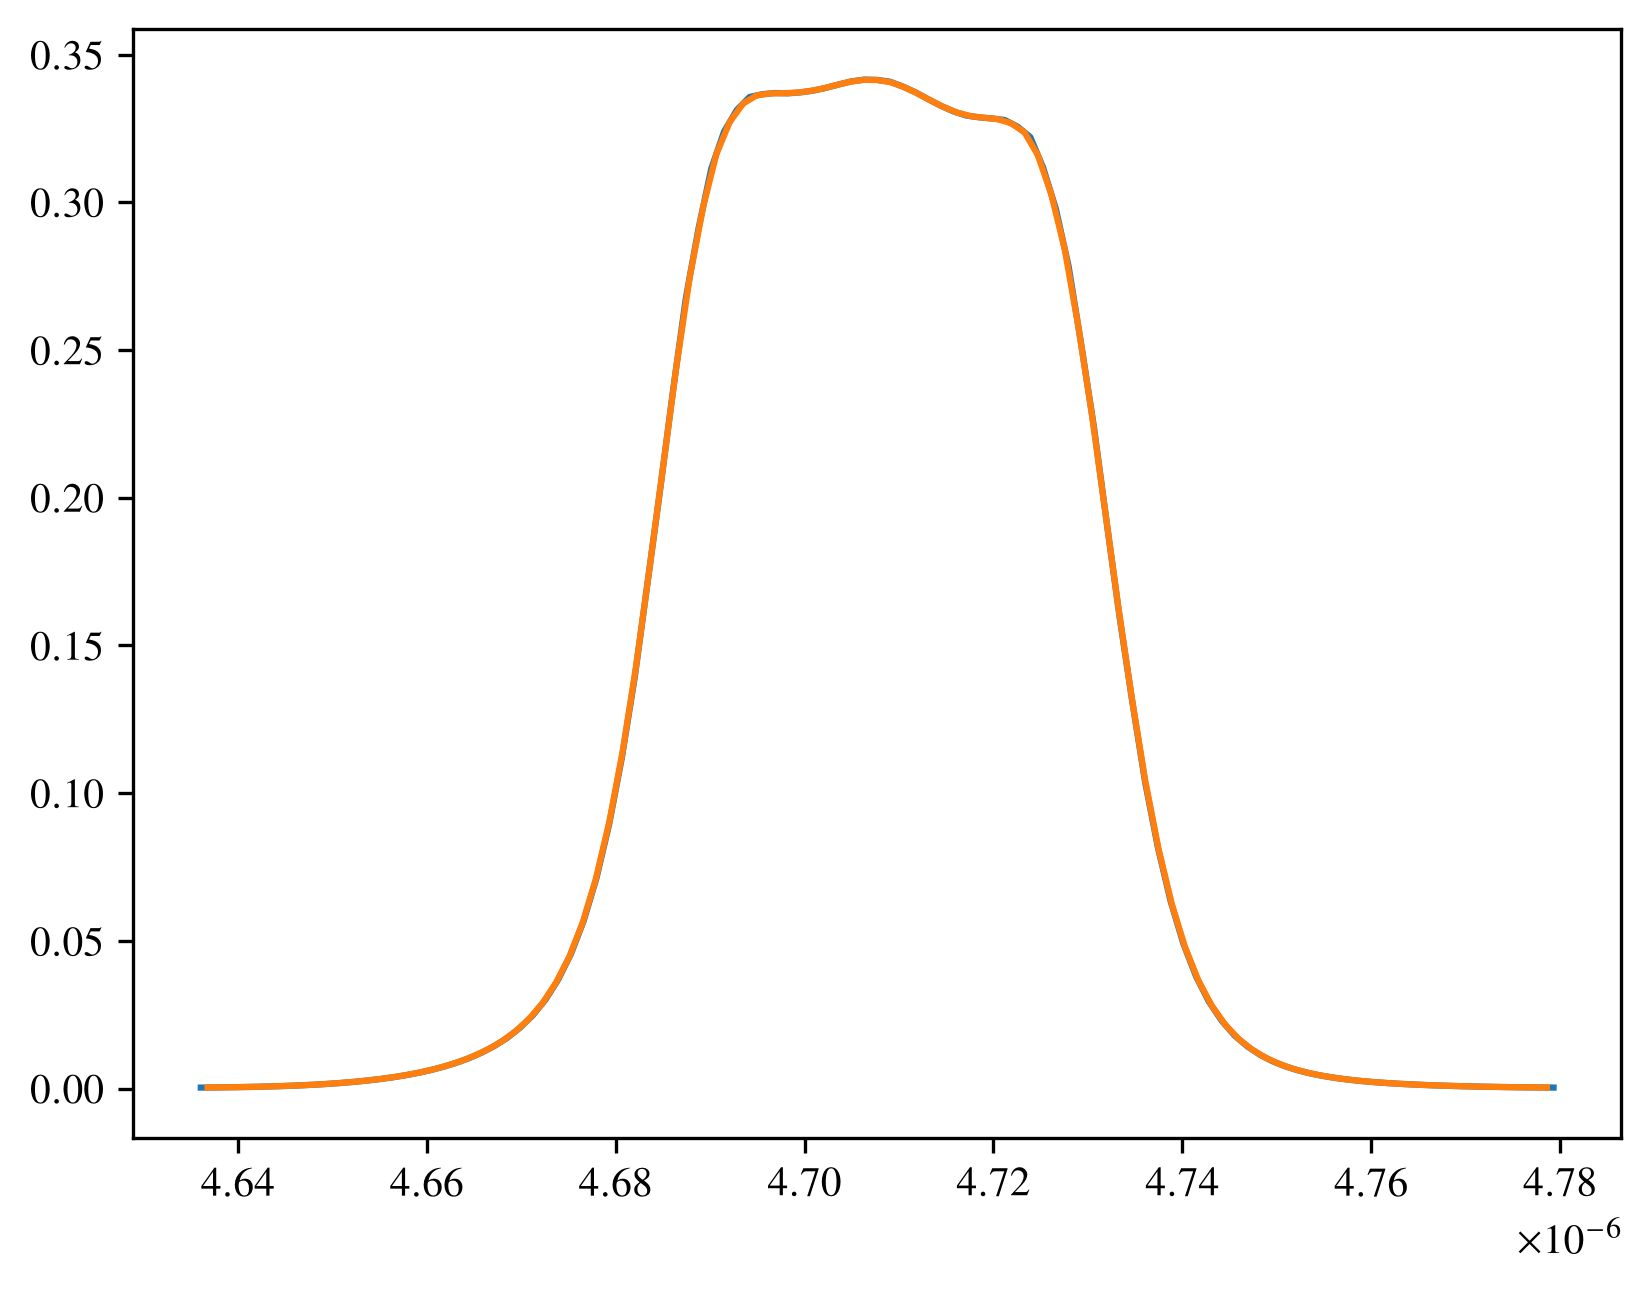

In [268]:
# importing the filters
# choose filter
long = True # choose long or short wavelengths
arr = onp.loadtxt('nircam_filts/f470n.txt')
wave_um = arr[:, 0]
throughput = arr[:, 1]

wave_m = wave_um * 1e-6

# truncating to remove zeros
through_thresh = 1e-3*np.max(throughput)

waves_trim = wave_m[throughput>through_thresh]
throughput_trim = throughput[throughput>through_thresh]

wave_bin, throughput_bin, _ = bin_filter_midpoints(waves_trim, throughput_trim, 101)
plt.plot(waves_trim, throughput_trim)
plt.plot(wave_bin, throughput_bin)
plt.show()

In [269]:
from __future__ import annotations

import jax
import jax.numpy as jnp
import equinox as eqx

import dLux as dl
from dLux.psfs import PSF
from dLux.wavefronts import Wavefront


class MappedAngularOpticalSystem(dl.AngularOpticalSystem):
    """
    AngularOpticalSystem variant that maps over wavelengths using jax.lax.map
    rather than eqx.filter_vmap over the full wavelength axis.

    This reduces peak memory by evaluating wavelengths in chunks.

    Parameters
    ----------
    wavelength_batch_size : int | None
        Number of wavelengths to process in parallel per chunk.

        - None: pure lax.map, effectively one wavelength at a time.
        - 1: one wavelength at a time.
        - N: process N wavelengths at a time using vmap internally.
        - 0: equivalent to full vmap, i.e. basically the original memory pattern.
    """

    wavelength_batch_size: int | None = eqx.field(static=True)

    def __init__(
        self,
        wf_npixels: int,
        diameter: float,
        layers,
        psf_npixels: int,
        psf_pixel_scale: float,
        oversample: int = 1,
        wavelength_batch_size: int | None = 8,
    ):
        super().__init__(
            wf_npixels=wf_npixels,
            diameter=diameter,
            layers=layers,
            psf_npixels=psf_npixels,
            psf_pixel_scale=psf_pixel_scale,
            oversample=oversample,
        )

        if wavelength_batch_size is not None:
            wavelength_batch_size = int(wavelength_batch_size)
            if wavelength_batch_size < 0:
                raise ValueError("wavelength_batch_size must be None, 0, or a positive int.")

        self.wavelength_batch_size = wavelength_batch_size

    def propagate(
        self,
        wavelengths,
        offset=None,
        weights=None,
        return_wf: bool = False,
        return_psf: bool = False,
    ):
        """
        Polychromatic propagation using jax.lax.map over wavelength.

        Same semantics as dLux.OpticalSystem.propagate, but with chunked
        wavelength evaluation.
        """
        if return_wf and return_psf:
            raise ValueError(
                "Cannot return both Wavefront and PSF objects. "
                "Choose return_wf=True or return_psf=True."
            )

        wavelengths = jnp.atleast_1d(wavelengths)

        if weights is None:
            weights = jnp.ones_like(wavelengths) / wavelengths.size
        else:
            weights = jnp.atleast_1d(weights)

        if weights.shape != wavelengths.shape:
            raise ValueError(
                f"wavelengths and weights must have the same shape, got "
                f"{wavelengths.shape} and {weights.shape}."
            )

        if offset is None:
            offset = jnp.zeros(2)
        else:
            offset = jnp.asarray(offset)

        if offset.shape != (2,):
            raise ValueError(f"offset must have shape (2,), got {offset.shape}.")

        def prop_one(x):
            wavelength, weight = x

            # Important: return_wf=True here so we can weight amplitudes before
            # taking |E|^2, exactly as in dLux's current implementation.
            wf = self.propagate_mono(
                wavelength=wavelength,
                offset=offset,
                return_wf=True,
            )

            return wf.multiply("phasor", jnp.sqrt(weight))

        wf = jax.lax.map(
            prop_one,
            (wavelengths, weights),
            batch_size=self.wavelength_batch_size,
        )

        if return_wf:
            return wf

        psf = wf.psf.sum(axis=0)

        if return_psf:
            return PSF(psf, wf.pixel_scale.mean())

        return psf
    

from __future__ import annotations

import jax
import jax.numpy as np
from jax import lax
from jax import Array

from dLux.optical_systems import AngularOpticalSystem
from dLux.psfs import PSF


class ScannedAngularOpticalSystem(AngularOpticalSystem):
    """
    Memory-safe AngularOpticalSystem.

    This replaces dLux's default wavelength-vectorised propagation with a
    lax.scan over wavelengths, accumulating the final polychromatic PSF directly.

    Main difference from dLux's default propagate:
        default: propagate all wavelengths -> store wavelength stack -> sum PSFs
        this:    propagate one wavelength -> add weighted PSF -> discard

    This is much more memory safe for large wavelength grids.

    Notes
    -----
    This class intentionally does not support return_wf=True, because returning
    a per-wavelength Wavefront object would require storing the full wavelength
    stack, which defeats the point of the class.
    """

    def propagate(
        self,
        wavelengths: Array,
        offset: Array | None = None,
        weights: Array | None = None,
        return_wf: bool = False,
        return_psf: bool = False,
    ) -> Array | PSF:
        if return_wf:
            raise NotImplementedError(
                "ScannedAngularOpticalSystem does not support return_wf=True, "
                "because that would require storing the full wavelength stack."
            )

        if return_wf and return_psf:
            raise ValueError(
                "Cannot return both Wavefront and PSF objects. Choose one."
            )

        wavelengths = np.atleast_1d(wavelengths)

        if weights is None:
            weights = np.ones_like(wavelengths) / wavelengths.size
        else:
            weights = np.atleast_1d(weights)

        if weights.shape != wavelengths.shape:
            raise ValueError(
                f"wavelengths and weights must have the same shape, got "
                f"{wavelengths.shape} and {weights.shape}."
            )

        if offset is None:
            offset = np.zeros(2)
        else:
            offset = np.asarray(offset)

        if offset.shape != (2,):
            raise ValueError(
                f"offset must have shape (2,), got {offset.shape}."
            )

        # Initialise accumulator with a zero PSF of the correct shape.
        #
        # This does perform one extra monochromatic propagation. That is usually
        # acceptable, and it avoids hard-coding the output shape.
        psf0 = np.zeros_like(
            self.propagate_mono(
                wavelength=wavelengths[0],
                offset=offset,
                return_wf=False,
            )
        )

        def step(psf_acc, x):
            wavelength, weight = x

            psf_i = self.propagate_mono(
                wavelength=wavelength,
                offset=offset,
                return_wf=False,
            )

            # dLux default does:
            #   wf_i.multiply("phasor", sqrt(weight)).psf
            #
            # Since psf = |phasor|^2, this is exactly:
            #   weight * psf_i
            psf_acc = psf_acc + weight * psf_i

            return psf_acc, None

        psf, _ = lax.scan(
            step,
            psf0,
            xs=(wavelengths, weights),
        )

        if return_psf:
            # AngularOpticalSystem.to_focus uses:
            #   true_pixel_scale = self.psf_pixel_scale / self.oversample
            #
            # dLux's default return_psf uses wf.pixel_scale.mean(), which should
            # be this same final angular pixel scale in arcsec units for the
            # AngularOpticalSystem.
            pixel_scale = self.psf_pixel_scale / self.oversample
            return PSF(psf, pixel_scale)

        return psf

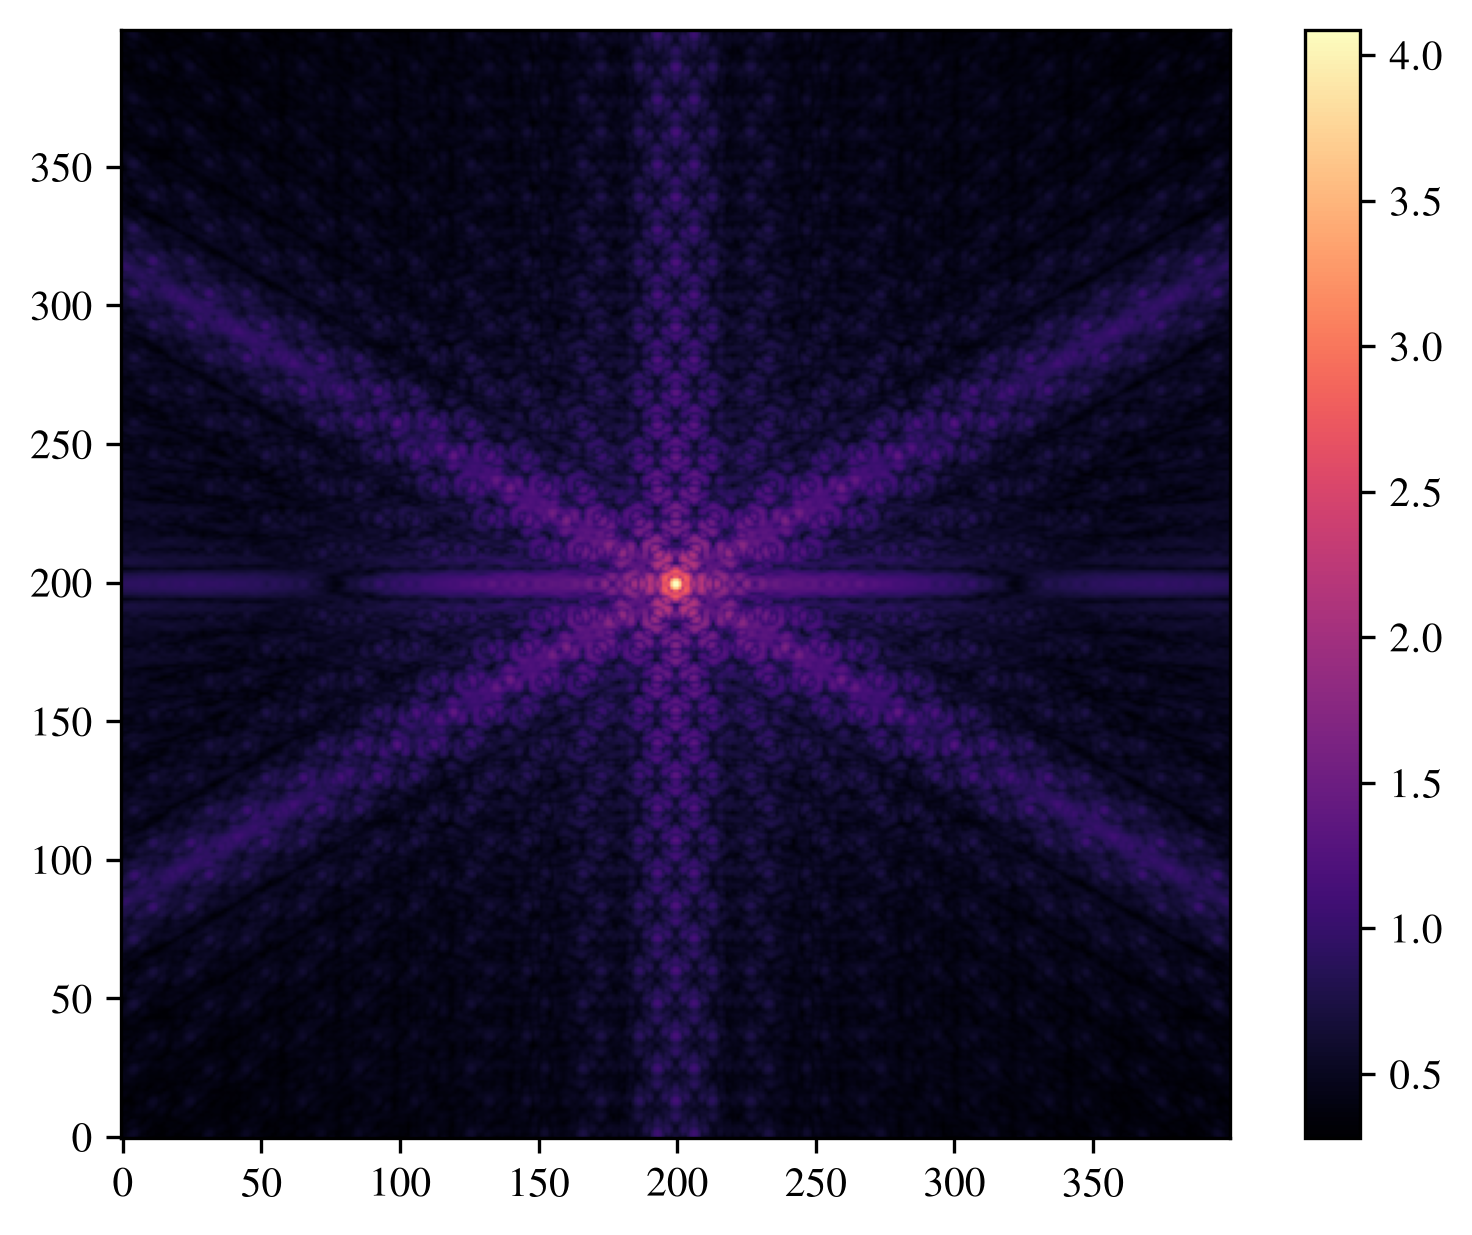

77999.99999999962


In [270]:
layers = [
    (
        'aperture',
        dl.TransmissiveLayer(aperture, True)
    )
]

psf_npix = 400 #sub400p array
psf_pscale_l = 0.063 #arcsec per pixel, long wavelength channel
psf_pscale_s = 0.031 #arcsec per pixel, short wavelength channel
oversample = 4 #should be enough

if long == True:
    psf_pixel_scale = psf_pscale_l
else:
    psf_pixel_scale = psf_pscale_s

# for some reason scanned truly saves memory but batched doesn't
# so do scanned
optics = ScannedAngularOpticalSystem(
    wf_npix,
    diameter,
    layers,
    psf_npix,
    psf_pixel_scale,
    oversample,
)

optics_tiny = ScannedAngularOpticalSystem(
    wf_npix,
    diameter,
    layers,
    2,
    psf_pixel_scale,
    oversample
)

detector = dl.LayeredDetector([
    (
        'downsample',
        dl.detector_layers.Downsample(kernel_size=oversample)
    )
])

## time for the source
N = throughput_bin.size

spectrum_model = CombinedBasisSpectrum(wave_bin, throughput_bin, np.ones(N), np.eye(N))

source_model = dl.PointSource(
    spectrum=spectrum_model
)

instrument = dl.Telescope(optics, source_model, detector)
instrument_tiny = dl.Telescope(optics_tiny, source_model, detector)

injected_tiny = np.ones(N)/N * 1e6
img_tiny = model_psf(injected_tiny, instrument_tiny)

full_well_s = 1e5 # 100,000 photoelectrons
full_well_l = 78e3 # 78k photoelectrons

if long == True:
    full_well = full_well_l
else:
    full_well = full_well_s

injected_spectrum = injected_tiny * full_well/np.max(img_tiny)

img_full = model_psf(injected_spectrum, instrument)

plt.imshow(img_full**0.125, cmap='magma')
plt.colorbar()
plt.show()

print(np.max(img_full))

In [271]:
## now we need to model a source properly 

# the pipeline does an "objectively more chopped" version of this.
# here we define integration time as (n_g - 1)*t_g.
# basically time between first and last group
# i'm sure this will be fine..

def loss_fn(params, model, data):
    spectrum = params['spectrum']
    # img = model_psf_hermite(spectrum, model, wavelengths_coarse)
    img = model_psf(spectrum, model)
    # loss = -poisson_loglike_gamma(data, img).sum()
    # for correct gaussian approximation, must use the data as the error term

    # gonna use the "rapid" configuration. 1 frame per group, 10 groups (maximum)
    n_g = 10 # number of groups
    m_f = 1 # number of (non-skipped) frames per group
    t_f = 1.66 # time per frame (seconds), SUB400P
    t_g = t_f * m_f # time per group (seconds). Here no skipped frames so just simple multiplication

    sigma_r_l = 13.25/np.sqrt(2) #readout noise per frame (electrons). have to divide by sqrt 2 because they report it for 2 frames
    sigma_r_s = 15.77/np.sqrt(2)
    if long == True:
        sigma_r = sigma_r_l
    else:
        sigma_r = sigma_r_s

    t_int = (n_g - 1)*t_g
    b = data/t_int # flux rate (electrons per second). use data.

    total_var = (6/5) * (n_g**2 + 1)*(n_g - 1)/(n_g*(n_g+1)) * b*t_g * (1 - (5/3)*(m_f**2-1)/(m_f*(n_g**2+1))*(t_f/t_g)) + 12*(n_g-1)/(m_f*n_g*(n_g+1))*sigma_r**2

    loss = -normal_logpdf(data, img, np.sqrt(total_var)).sum()
    return loss

params = {
    "spectrum": injected_spectrum
}

# total derangement incoming
f = lambda params: loss_fn(params, instrument, img_full)

from zodiax.diffops import hessian
H, unflatten = hessian(f, params)

In [272]:
eigvals, eigvecs = np.linalg.eigh(H)

idx = np.argsort(eigvals)[::-1]

eigvals = eigvals[idx]
eigvecs = eigvecs[:, idx]
mode_spectra = np.fft.rfft(eigvecs, axis=0)

# Optional sign convention
for i in range(eigvecs.shape[0]):
    eigvecs = eigvecs.at[:, i].mul(np.sign(np.mean(eigvecs[:10, i])))

a = eigvecs.T @ injected_spectrum

n_int = 1 # number of integrations
eigvals *= n_int 

relstd = 1 / (np.abs(a[0]) * np.sqrt(eigvals))

# no. constrained modes
n_modes = np.argmax(relstd>0.1)

# effective R value
cutoff = 0.25 * np.max(throughput)
wlidx = np.where(throughput > cutoff)[0]

fidx = wlidx[0]
lidx = wlidx[-1]

bw = wave_m[lidx] - wave_m[fidx]
c_wl = (wave_m[lidx] + wave_m[fidx])/2

R = c_wl*n_modes/bw

eigvals_all.append(eigvals)
a0s_all.append(a[0])
print(n_modes)
print(R)
# print(a0s_all)

2
165.90476022744593


In [ ]:
# a0s_all_array = np.array(a0s_all)

In [ ]:
# np.save('nircam_a0s.npy', a0s_all_array)

In [ ]:
# eigvals_all_array = np.array(eigvals_all)

In [ ]:
# np.save('nircam_eigvals.npy', eigvals_all_array)

In [129]:
bw

np.float64(1.3839999999999998e-06)

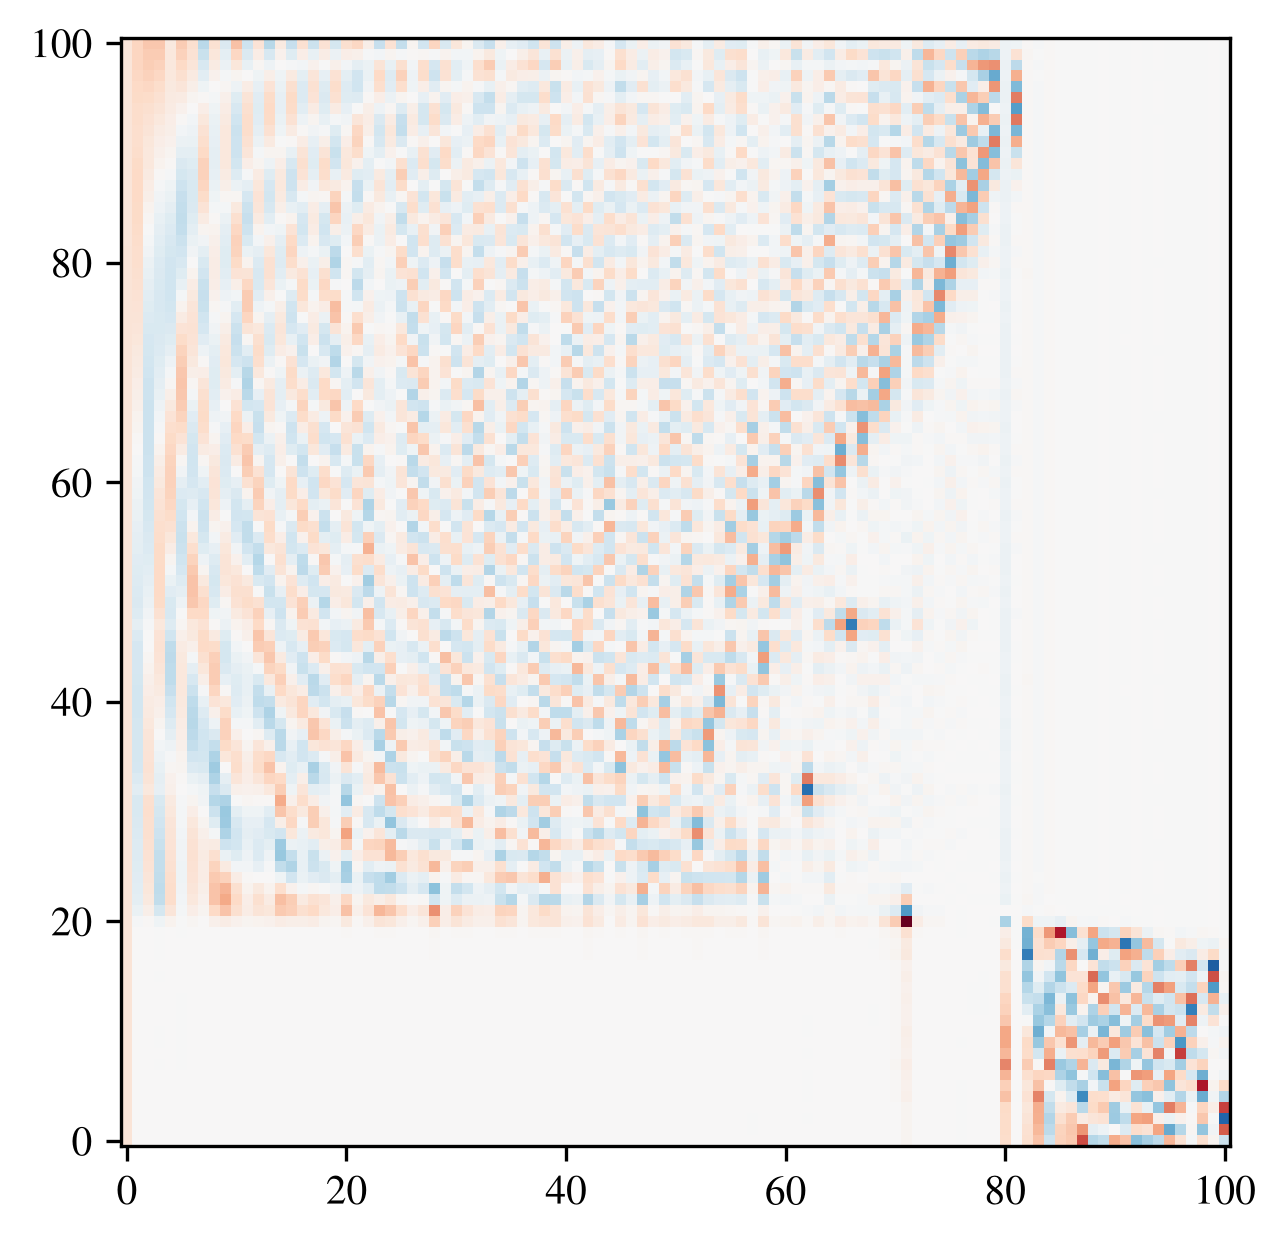

In [130]:
v = np.max(np.abs(eigvecs))

plt.imshow(eigvecs, cmap='RdBu_r', vmin=-v, vmax=v)
plt.show()

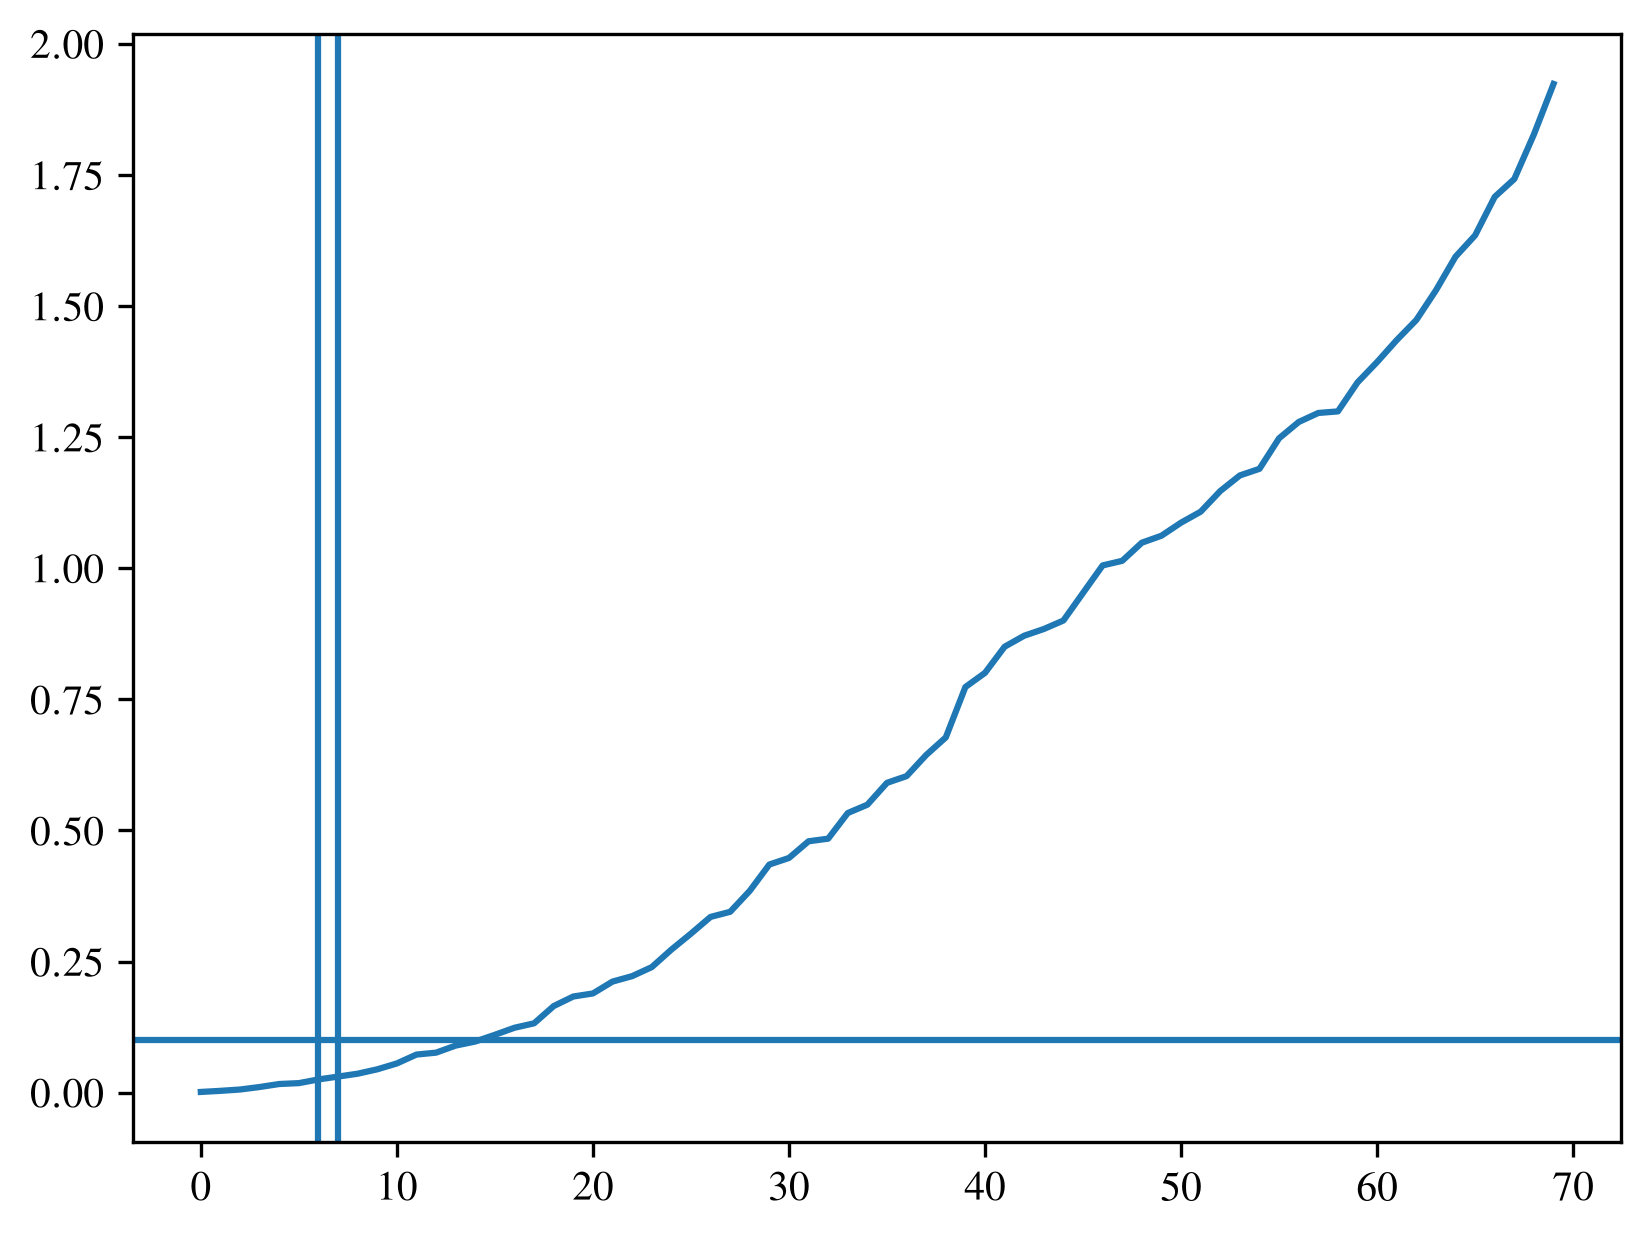

In [131]:
plt.plot(relstd[:70])
plt.axhline(0.1)
plt.axvline(7)
plt.axvline(6)